# Notebook 2

In [1]:
%matplotlib inline
import networkx as nx
import matplotlib.pyplot as plt

### Clustering coefficient

The vertex clustering coefficient describes the probability that the first neighbors of this node are also first neighbors to each other. 

###### # Example 1

In [2]:
g = nx.Graph()

In [3]:
e = list(zip('A A A B B C C D E E F T'.split(), 'K B C C K E F E F H G J'.split()))

In [4]:
g.add_edges_from(e)

In [5]:
g.edges()

EdgeView([('A', 'K'), ('A', 'B'), ('A', 'C'), ('K', 'B'), ('B', 'C'), ('C', 'E'), ('C', 'F'), ('E', 'D'), ('E', 'F'), ('E', 'H'), ('F', 'G'), ('T', 'J')])

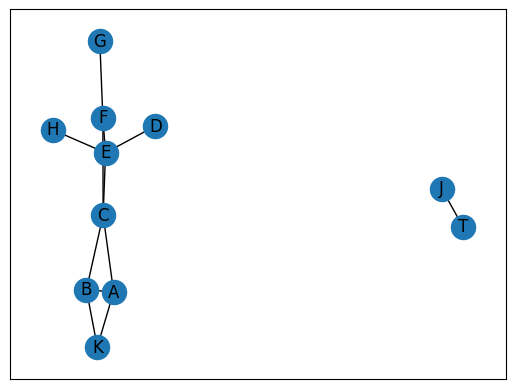

In [6]:
nx.draw_networkx(g)

In [7]:
def plot_degree_dist(G):
    degrees = [G.degree(n) for n in G.nodes()]
    plt.hist(degrees)
    plt.show()

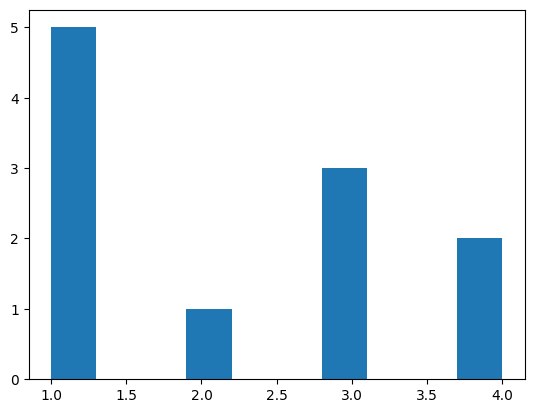

In [8]:
plot_degree_dist(g)

Local clustering coefficient:

(For nodes with a degree <= 2 we assume that LCCoeff = 0)

In [9]:
nx.clustering(g, 'F'), nx.clustering(g, 'A'), nx.clustering(g, 'J')

(0.3333333333333333, 0.6666666666666666, 0)

Global clustering coefficient:

In [10]:
nx.average_clustering(g)

0.28787878787878785

![open triads and triangles](./2/tri.png)

Transitivity: the ratio of the number of triangles and the number of open triads in the network. 

In [11]:
nx.transitivity(g)

0.4090909090909091

###### # Example2

![clustering coeffs and transitivity](./2/transitivity.png)

### Distances

Path length: Number of edges between two vertices. 

Distance: Smallest number of edges between vertices. 

###### # Example 3

In [12]:
g = nx.Graph()

In [13]:
g.add_edges_from(
    [
        ('A', 'K'),
        ('A', 'B'),
        ('B', 'K'),
        ('B', 'C'),
        ('C', 'F'),
        ('C', 'E'),
        ('F', 'E'),
        ('F', 'G'),
        ('D', 'E'),
        ('E', 'H'),
        ('E', 'I'),
        ('I', 'J')
    ]
)

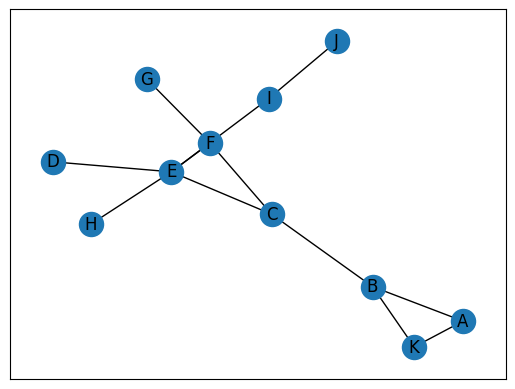

In [14]:
nx.draw_networkx(g)

We are looking for the shortest path between vertices `A` and` H`. 

In [15]:
nx.shortest_path(g, 'A', 'H')

['A', 'B', 'C', 'E', 'H']

We check the length of this path. 

In [16]:
nx.shortest_path_length(g, 'A', 'H')

4

In [17]:
g.add_edges_from(
    [
        ('G', 'T')
    ]
)

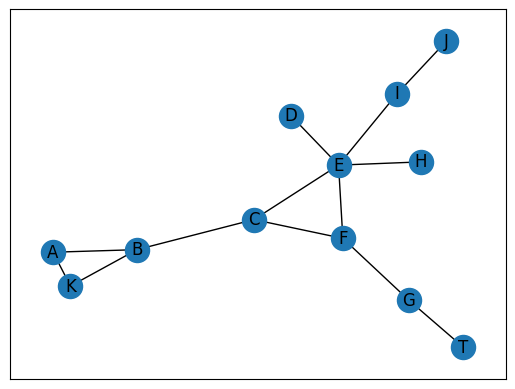

In [18]:
nx.draw_networkx(g)

Average distance:

In [19]:
nx.average_shortest_path_length(g)

2.712121212121212

Diameter: the greatest possible distance between two vertices.

In [20]:
nx.diameter(g)

5

Eccentricity: distance of a given vertex to the most distant vertex in the graph.

In [21]:
nx.eccentricity(g)

{'A': 5,
 'K': 5,
 'B': 4,
 'C': 3,
 'F': 3,
 'E': 3,
 'G': 4,
 'D': 4,
 'H': 4,
 'I': 4,
 'J': 5,
 'T': 5}

Radius: the smallest eccentricity of the graph.

In [22]:
nx.radius(g)

3

Periphery: A set of vertices whose eccentricity is equal to the diameter of the graph.

In [23]:
nx.periphery(g)

['A', 'K', 'J', 'T']

Center: A set of vertices whose eccentricity is equal to the radius of the graph.

In [24]:
nx.center(g)

['C', 'F', 'E']

###### # Example 4 (undirected graph)

In [25]:
g = nx.karate_club_graph()
g = nx.convert_node_labels_to_integers(g, first_label=1)

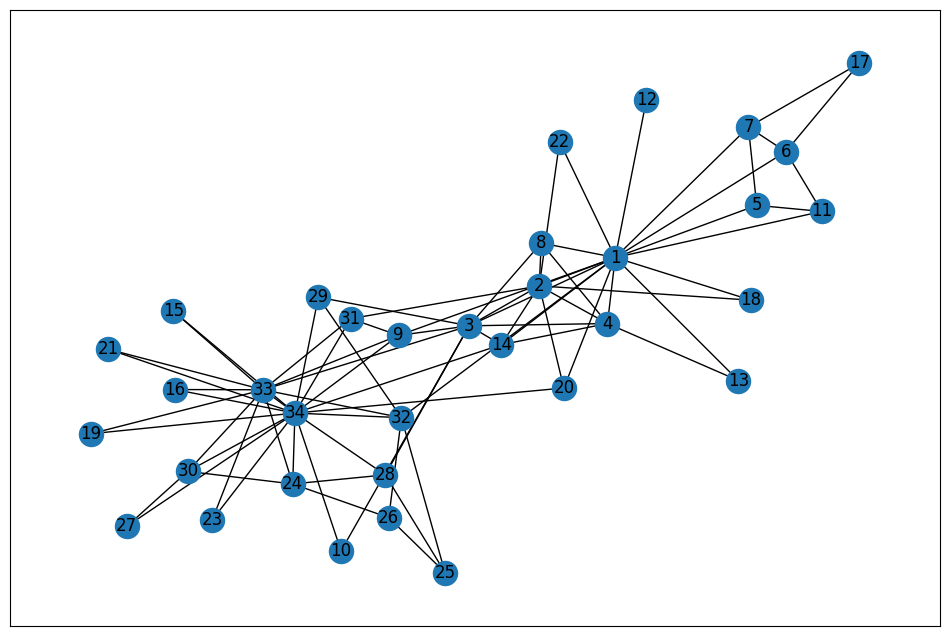

In [26]:
plt.figure(figsize=(12,8))
nx.draw_networkx(g)

In [27]:
def info(graph):
    s = 'radius = {0}\ndiameter = {1}\ncenter = {2}\nperiphery = {3}'
    return s.format(nx.radius(graph),
                    nx.diameter(graph),
                    nx.center(graph),
                    nx.periphery(graph))

In [28]:
print(info(g))

radius = 3
diameter = 5
center = [1, 2, 3, 4, 9, 14, 20, 32]
periphery = [15, 16, 17, 19, 21, 23, 24, 27, 30]


### Graph consistency 

An undirected graph is consistent if there is a path connecting each pair of vertices. 

In [29]:
g = nx.Graph()
g.add_edges_from(
    [
        ('A', 'B'), ('A', 'E'), ('A', 'C'), ('A', 'N'), ('A', 'G'),
        ('B', 'A'), ('B', 'C'), ('B', 'D'), ('B', 'E'),
        ('C', 'A'), ('C', 'B'), ('C', 'D'), ('C', 'E'),
        ('D', 'C'), ('D', 'B'), ('D', 'E'),
        ('E', 'D'), ('E', 'C'), ('E', 'B'), ('E', 'A'),
        ('F', 'G'), ('F', 'I'), ('F', 'J'),        
        ('G', 'A'), ('G', 'F'), ('G', 'I'), ('G', 'H'),
        ('H', 'G'), ('H', 'I'),
        ('I', 'H'), ('I', 'G'), ('I', 'F'), ('I', 'J'),
        ('J', 'F'), ('J', 'G'), ('J', 'I'), ('J', 'O'),
        ('K', 'L'), ('K', 'M'), ('K', 'O'),
        ('L', 'K'), ('L', 'O'), ('L', 'M'), ('L', 'N'),
        ('M', 'L'), ('M', 'K'),
        ('N', 'A'), ('N', 'L'), ('N', 'O'),
    ]
)

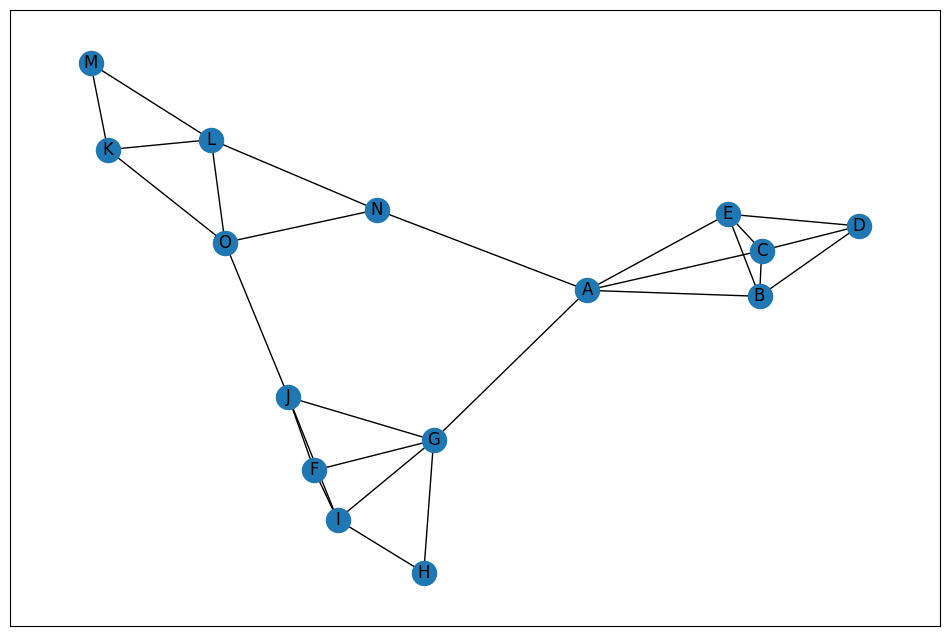

In [30]:
plt.figure(figsize=(12,8))
nx.draw_networkx(g)

In [31]:
nx.is_connected(g)

True

In [32]:
g_un = g.copy()

In [33]:
g_un.remove_edge('A','G')
g_un.remove_edge('A','N')
g_un.remove_edge('O','J')

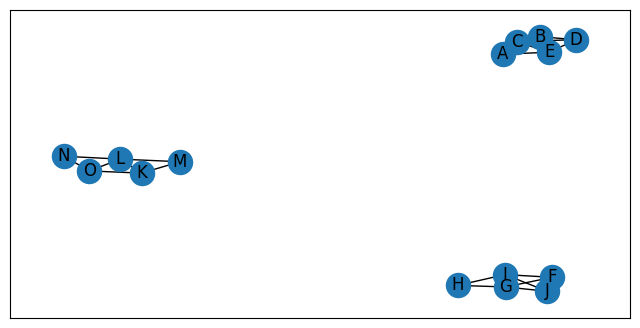

In [34]:
plt.figure(figsize=(8,4))
nx.draw_networkx(g_un)

In [35]:
nx.is_connected(g_un)

False

Connected component: a connected subgraph of G not included in a larger connected subgraph of G. In other words, a connected subgraph of a graph is one that can be 'separated' from the whole graph without removing the edges. A connected graph has one connected component. 

In [36]:
nx.number_connected_components(g_un)

3

In [37]:
sorted(nx.connected_components(g_un))

[{'A', 'B', 'C', 'D', 'E'},
 {'K', 'L', 'M', 'N', 'O'},
 {'F', 'G', 'H', 'I', 'J'}]

In [38]:
nx.node_connected_component(g_un, 'A')

{'A', 'B', 'C', 'D', 'E'}

In [39]:
nx.node_connected_component(g_un, 'H')

{'F', 'G', 'H', 'I', 'J'}

In [40]:
nx.node_connected_component(g_un, 'M')

{'K', 'L', 'M', 'N', 'O'}

### Robustness

Ability to maintain general structural properties in case of failure or attack situations (e.g. edge removal).

###### # Example 5

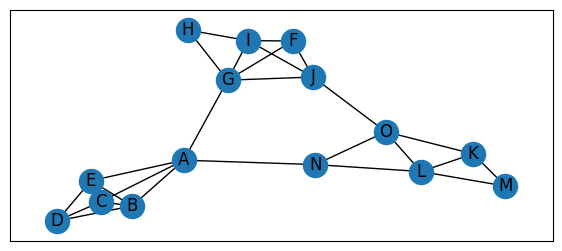

In [41]:
plt.figure(figsize=(7,3))
nx.draw_networkx(g)

In [42]:
nx.node_connectivity(g), nx.minimum_node_cut(g)

(1, {'A'})

In [43]:
nx.edge_connectivity(g), nx.minimum_edge_cut(g)

(2, {('K', 'M'), ('L', 'M')})

Robust nets are characterized by large minimal truncations of vertices and edges, i.e. a lot of vertices / edges have to be removed to make the graph no longer consistent.

In [44]:
sorted(nx.all_simple_paths(g, 'G', 'L'))

[['G', 'A', 'N', 'L'],
 ['G', 'A', 'N', 'O', 'K', 'L'],
 ['G', 'A', 'N', 'O', 'K', 'M', 'L'],
 ['G', 'A', 'N', 'O', 'L'],
 ['G', 'F', 'I', 'J', 'O', 'K', 'L'],
 ['G', 'F', 'I', 'J', 'O', 'K', 'M', 'L'],
 ['G', 'F', 'I', 'J', 'O', 'L'],
 ['G', 'F', 'I', 'J', 'O', 'N', 'L'],
 ['G', 'F', 'J', 'O', 'K', 'L'],
 ['G', 'F', 'J', 'O', 'K', 'M', 'L'],
 ['G', 'F', 'J', 'O', 'L'],
 ['G', 'F', 'J', 'O', 'N', 'L'],
 ['G', 'H', 'I', 'F', 'J', 'O', 'K', 'L'],
 ['G', 'H', 'I', 'F', 'J', 'O', 'K', 'M', 'L'],
 ['G', 'H', 'I', 'F', 'J', 'O', 'L'],
 ['G', 'H', 'I', 'F', 'J', 'O', 'N', 'L'],
 ['G', 'H', 'I', 'J', 'O', 'K', 'L'],
 ['G', 'H', 'I', 'J', 'O', 'K', 'M', 'L'],
 ['G', 'H', 'I', 'J', 'O', 'L'],
 ['G', 'H', 'I', 'J', 'O', 'N', 'L'],
 ['G', 'I', 'F', 'J', 'O', 'K', 'L'],
 ['G', 'I', 'F', 'J', 'O', 'K', 'M', 'L'],
 ['G', 'I', 'F', 'J', 'O', 'L'],
 ['G', 'I', 'F', 'J', 'O', 'N', 'L'],
 ['G', 'I', 'J', 'O', 'K', 'L'],
 ['G', 'I', 'J', 'O', 'K', 'M', 'L'],
 ['G', 'I', 'J', 'O', 'L'],
 ['G', 'I', 'J', 'O

### Graph visualization 

In [45]:
layouts = [x for x in nx.__dir__() if x.endswith('_layout')]
layouts

['bipartite_layout',
 'circular_layout',
 'kamada_kawai_layout',
 'random_layout',
 'rescale_layout',
 'shell_layout',
 'spring_layout',
 'spectral_layout',
 'planar_layout',
 'fruchterman_reingold_layout',
 'spiral_layout',
 'multipartite_layout',
 'arf_layout']

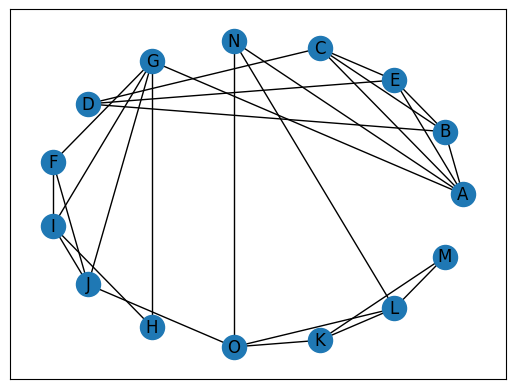

In [46]:
pos = nx.circular_layout(g)
nx.draw_networkx(g, pos)

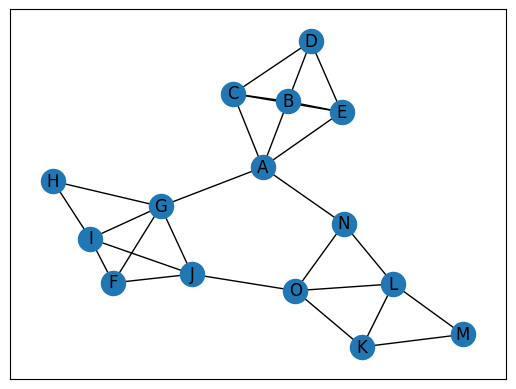

In [47]:
pos = nx.kamada_kawai_layout(g)
nx.draw_networkx(g, pos)

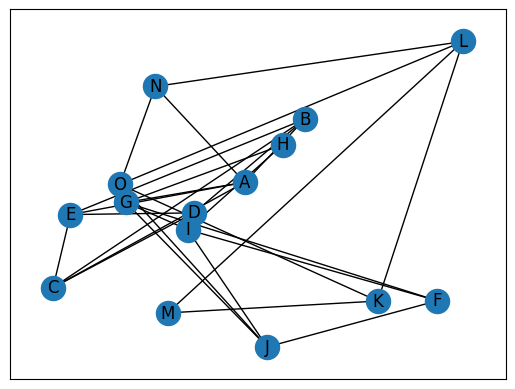

In [48]:
pos = nx.random_layout(g) 
nx.draw_networkx(g, pos)

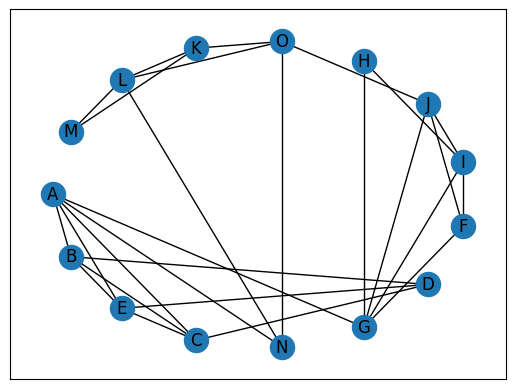

In [49]:
pos = nx.shell_layout(g)
nx.draw_networkx(g, pos)

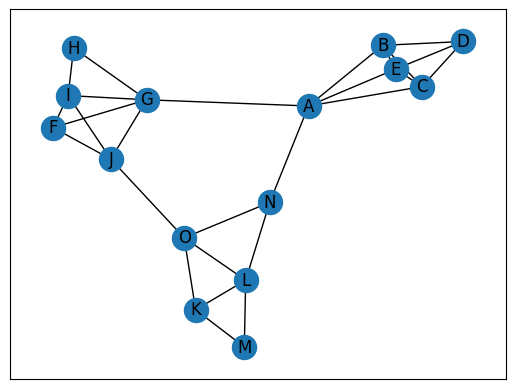

In [50]:
pos = nx.spring_layout(g)
nx.draw_networkx(g, pos)

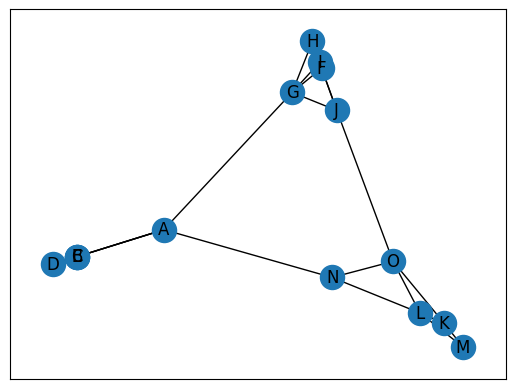

In [51]:
pos = nx.spectral_layout(g)
nx.draw_networkx(g, pos)

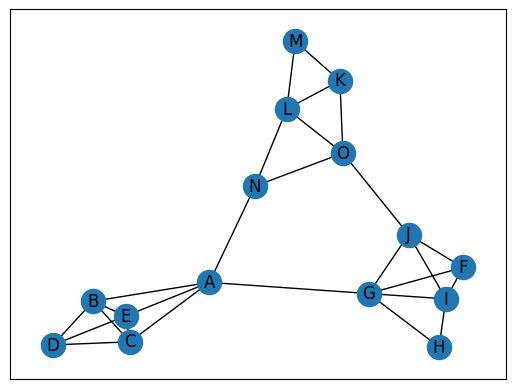

In [52]:
pos = nx.fruchterman_reingold_layout(g)
nx.draw_networkx(g, pos)